In [1]:
from google.colab import drive
drive.mount('/content/drive')

print("Google Drive est monté !")

Mounted at /content/drive
Google Drive est monté !


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
import warnings
warnings.simplefilter("ignore")

In [4]:

BASE_PATH = '/content/drive/MyDrive/Colab Notebooks/MLOPS-hotelReservation/'

test_path = BASE_PATH + 'test.csv'
train_path = BASE_PATH + 'train.csv'

print(f"Chemin vers les données de test : {test_path}")
print(f"Chemin vers les données d'entrainement : {train_path}")


Chemin vers les données de test : /content/drive/MyDrive/Colab Notebooks/MLOPS-hotelReservation/test.csv
Chemin vers les données d'entrainement : /content/drive/MyDrive/Colab Notebooks/MLOPS-hotelReservation/train.csv


In [5]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

In [6]:
train_df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN25630,2,1,2,1,Meal Plan 1,0,Room_Type 1,26,2017,10,17,Online,0,0,0,161.00,0,Not_Canceled
1,INN14474,2,1,1,1,Meal Plan 1,0,Room_Type 1,98,2018,7,16,Online,0,0,0,121.50,2,Not_Canceled
2,INN23721,2,0,0,3,Meal Plan 1,0,Room_Type 1,433,2018,9,8,Offline,0,0,0,70.00,0,Canceled
3,INN05844,2,0,2,5,Meal Plan 1,0,Room_Type 1,195,2018,8,8,Offline,0,0,0,72.25,0,Not_Canceled
4,INN18710,1,0,0,2,Meal Plan 1,0,Room_Type 1,188,2018,6,15,Offline,0,0,0,130.00,0,Canceled


In [7]:
train_df.drop(columns=['Booking_ID'], inplace=True)

In [8]:
train_df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,1,2,1,Meal Plan 1,0,Room_Type 1,26,2017,10,17,Online,0,0,0,161.00,0,Not_Canceled
1,2,1,1,1,Meal Plan 1,0,Room_Type 1,98,2018,7,16,Online,0,0,0,121.50,2,Not_Canceled
2,2,0,0,3,Meal Plan 1,0,Room_Type 1,433,2018,9,8,Offline,0,0,0,70.00,0,Canceled
3,2,0,2,5,Meal Plan 1,0,Room_Type 1,195,2018,8,8,Offline,0,0,0,72.25,0,Not_Canceled
4,1,0,0,2,Meal Plan 1,0,Room_Type 1,188,2018,6,15,Offline,0,0,0,130.00,0,Canceled


In [9]:
train_df.shape

(29020, 18)

In [10]:
train_df.columns

Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space',
       'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month',
       'arrival_date', 'market_segment_type', 'repeated_guest',
       'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled',
       'avg_price_per_room', 'no_of_special_requests', 'booking_status'],
      dtype='object')

In [11]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29020 entries, 0 to 29019
Data columns (total 18 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          29020 non-null  int64  
 1   no_of_children                        29020 non-null  int64  
 2   no_of_weekend_nights                  29020 non-null  int64  
 3   no_of_week_nights                     29020 non-null  int64  
 4   type_of_meal_plan                     29020 non-null  object 
 5   required_car_parking_space            29020 non-null  int64  
 6   room_type_reserved                    29020 non-null  object 
 7   lead_time                             29020 non-null  int64  
 8   arrival_year                          29020 non-null  int64  
 9   arrival_month                         29020 non-null  int64  
 10  arrival_date                          29020 non-null  int64  
 11  market_segment_

In [12]:
train_df.describe()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests
count,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000,29020.000000
mean,1.844280,0.106306,0.807822,2.202068,0.031943,85.376085,2017.820434,7.416506,15.598725,0.025775,0.023880,0.154721,103.501785,0.619917
std,0.518692,0.405391,0.868111,1.402801,0.175853,85.859070,0.383832,3.060058,8.740151,0.158467,0.375994,1.777787,35.137794,0.786348
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2017.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2018.000000,5.000000,8.000000,0.000000,0.000000,0.000000,80.500000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2018.000000,8.000000,16.000000,0.000000,0.000000,0.000000,99.850000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,127.000000,2018.000000,10.000000,23.000000,0.000000,0.000000,0.000000,120.120000,1.000000
max,4.000000,10.000000,6.000000,17.000000,1.000000,443.000000,2018.000000,12.000000,31.000000,1.000000,13.000000,58.000000,375.500000,5.000000


In [13]:
train_df.isna().sum()

,0
no_of_adults,0
no_of_children,0
no_of_weekend_nights,0
no_of_week_nights,0
type_of_meal_plan,0
required_car_parking_space,0
room_type_reserved,0
lead_time,0
arrival_year,0
arrival_month,0


In [14]:
train_df.duplicated().sum()

np.int64(7661)

In [15]:
train_df.drop_duplicates(inplace=True)

In [16]:
train_df.shape

(21359, 18)

In [17]:
train_df.columns

Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space',
       'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month',
       'arrival_date', 'market_segment_type', 'repeated_guest',
       'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled',
       'avg_price_per_room', 'no_of_special_requests', 'booking_status'],
      dtype='object')

In [18]:
train_df["no_of_adults"].value_counts()

,count
no_of_adults,
2,15489
1,3996
3,1748
0,113
4,13


In [19]:
train_df["no_of_children"].value_counts()

,count
no_of_children,
0,19251
1,1257
2,837
3,11
9,2
10,1


In [20]:
train_df["no_of_children"].value_counts() # il faut tester les autres aussi pour avoir une idées géneral

,count
no_of_children,
0,19251
1,1257
2,837
3,11
9,2
10,1


In [21]:
train_df["type_of_meal_plan"].value_counts()

,count
type_of_meal_plan,
Meal Plan 1,16759
Not Selected,3627
Meal Plan 2,969
Meal Plan 3,4


In [22]:
train_df["arrival_month"].value_counts()

,count
arrival_month,
10,2663
9,2525
8,2477
12,1928
7,1893
11,1817
4,1695
3,1611
6,1543


In [23]:
train_df["booking_status"].value_counts()

,count
booking_status,
Not_Canceled,15231
Canceled,6128


In [24]:
cat_cols = ['type_of_meal_plan','required_car_parking_space',
       'room_type_reserved','market_segment_type', 'repeated_guest','booking_status']

num_cols = ['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights','lead_time', 'arrival_year', 'arrival_month',
       'arrival_date','no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled',
       'avg_price_per_room', 'no_of_special_requests']

#### DATA ANALYSIS :

 Astuce :
Pour les variables les features numerique on utilise les histogrammes et les boxplot.

Pour les variables de catégories on utilise value_counts() + barplot.

In [25]:
data = train_df.copy()

In [26]:
data.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,1,2,1,Meal Plan 1,0,Room_Type 1,26,2017,10,17,Online,0,0,0,161.00,0,Not_Canceled
1,2,1,1,1,Meal Plan 1,0,Room_Type 1,98,2018,7,16,Online,0,0,0,121.50,2,Not_Canceled
2,2,0,0,3,Meal Plan 1,0,Room_Type 1,433,2018,9,8,Offline,0,0,0,70.00,0,Canceled
3,2,0,2,5,Meal Plan 1,0,Room_Type 1,195,2018,8,8,Offline,0,0,0,72.25,0,Not_Canceled
4,1,0,0,2,Meal Plan 1,0,Room_Type 1,188,2018,6,15,Offline,0,0,0,130.00,0,Canceled


##### UNVARIANTE ANALYSIS :

In [27]:
def num_plot_dist(data,num_features,kde=True,color=None,max_rows=30,bins=30):

  n = len(num_features)
  if n ==0:
    print("aucune colonne fournie!")
    return
  if n > max_rows:
    print(f"Attention : {n} colonnes — affichage des {max_rows} premières.")
    num_features = num_features[:max_rows]
    n = max_rows

  fig , axes = plt.subplots(n,2,figsize=(15,n*3))
  axes = np.atleast_2d(axes) #  # garantit axes[i,0] et axes[i,1]

  for i,col in enumerate(num_features):
    ser = data[col].dropna()

    sns.histplot(ser, bins=bins, kde=kde, ax=axes[i, 0], color=color)
    axes[i, 0].set_title(f"Histogram for {col}")

    sns.boxplot(x=ser, ax=axes[i, 1], color=color)
    axes[i, 1].set_title(f"Box Plot for {col}")

  plt.tight_layout()
  plt.show()

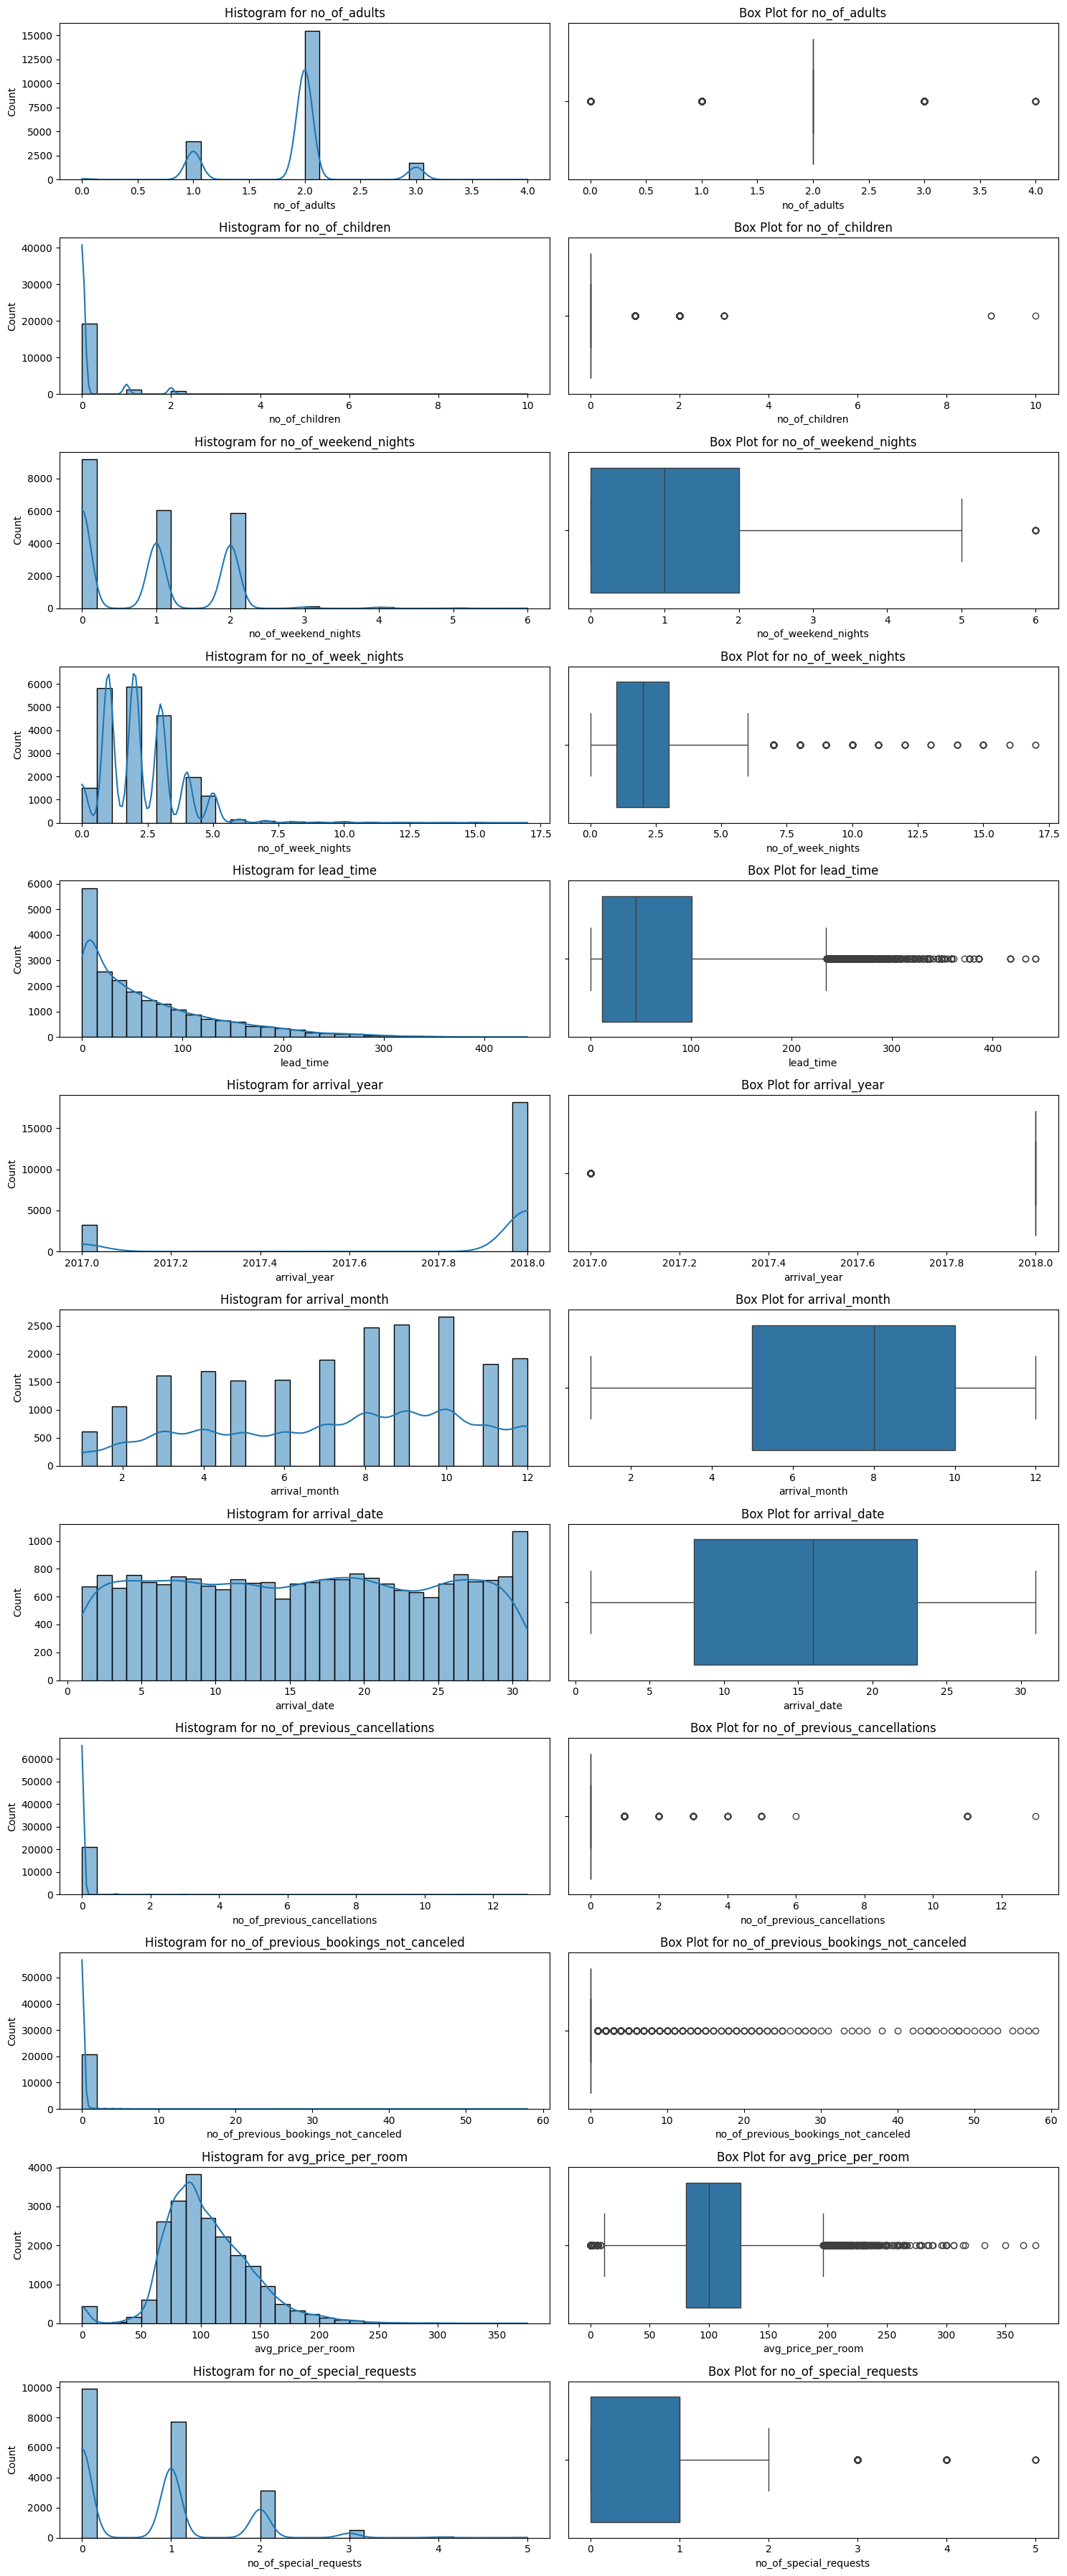

In [28]:
num_plot_dist(data,num_cols)

In [29]:
def plot_categorical_distribution(df: pd.DataFrame, cat_features: list,
                                  top_n: int = None, color: str = "skyblue",
                                  figsize=(10,6)):
    for cat_feature in cat_features:
        if cat_feature not in df.columns:
            print(f"Colonne '{cat_feature}' non trouvée dans le DataFrame.")
            continue

        counts = df[cat_feature].value_counts(dropna=False)
        if top_n:
            counts = counts.head(top_n)

        plt.figure(figsize=figsize)
        counts.plot(kind='bar', color=color)
        plt.title(f"{cat_feature} Distribution", fontsize=14)
        plt.xlabel(cat_feature, fontsize=12)
        plt.ylabel("Count", fontsize=12)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

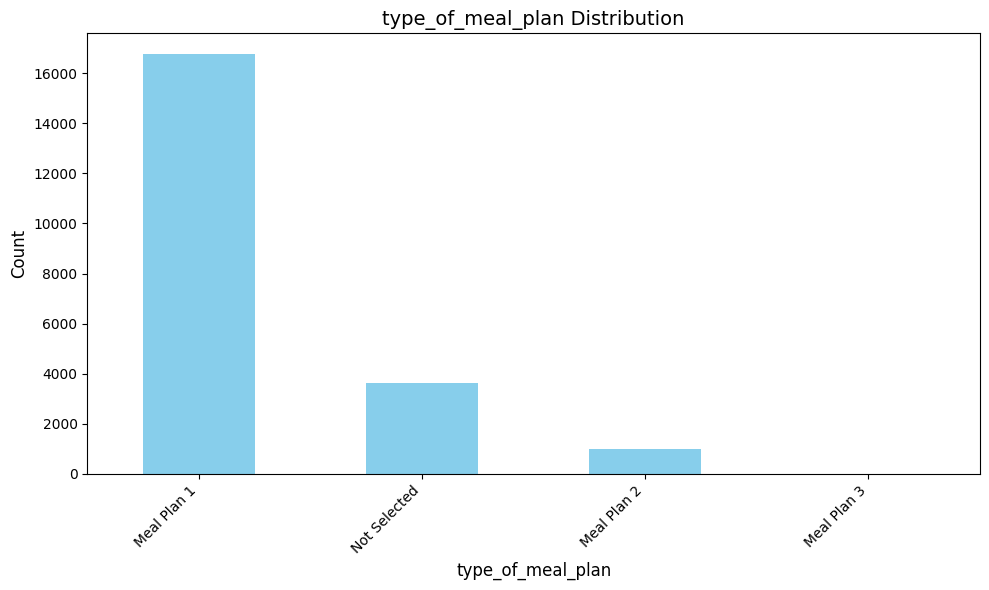

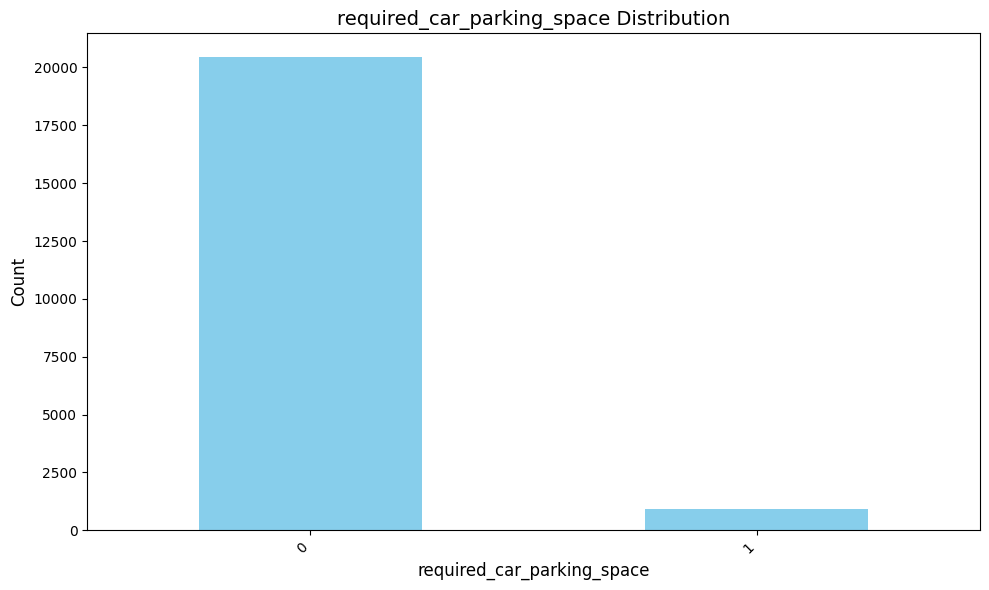

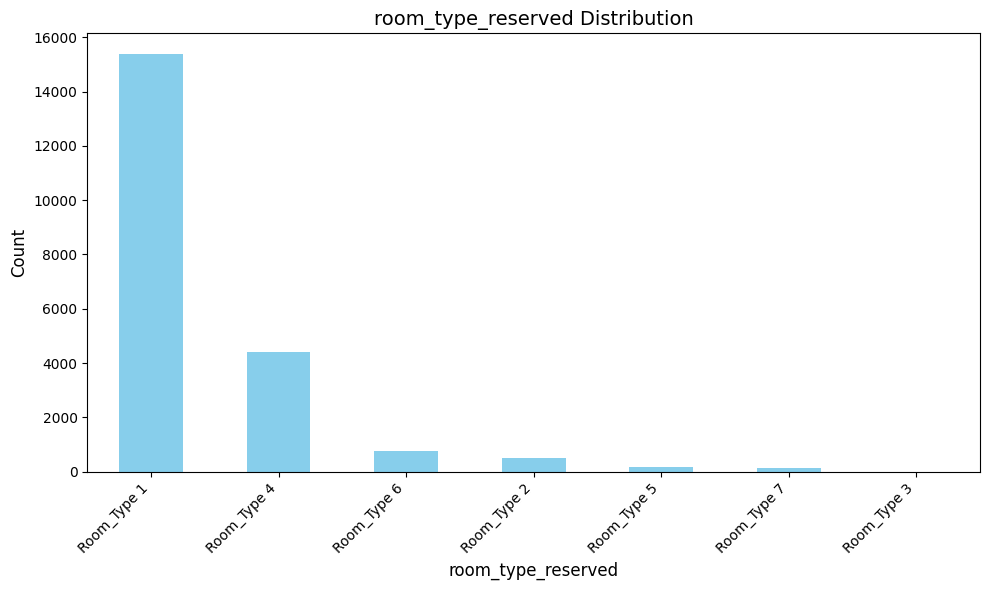

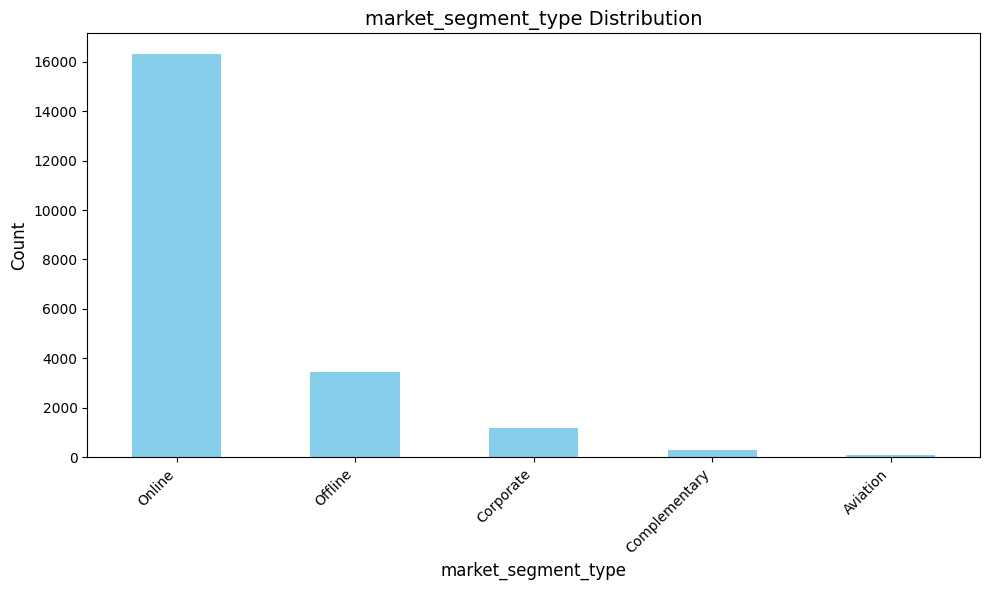

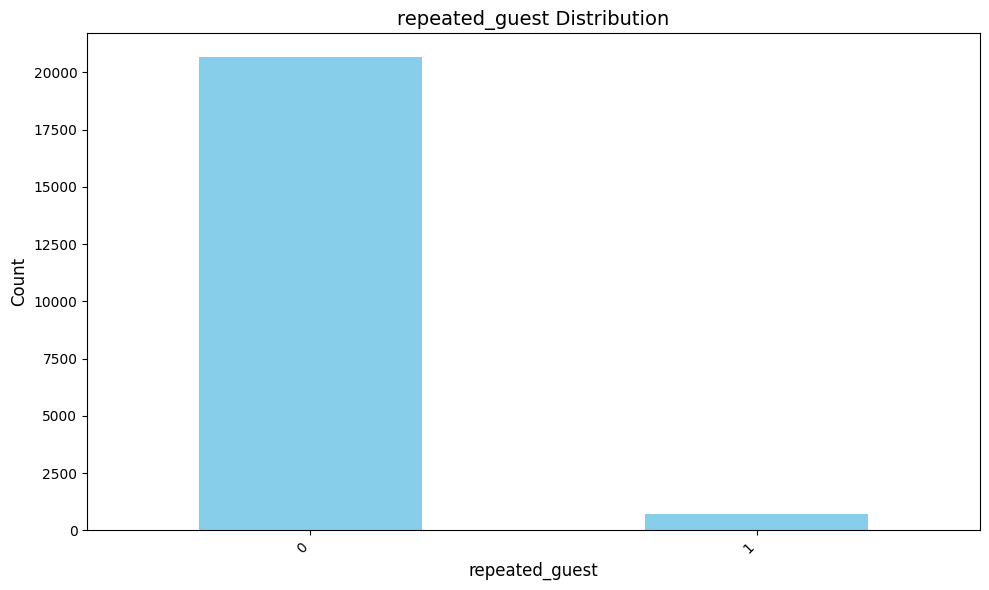

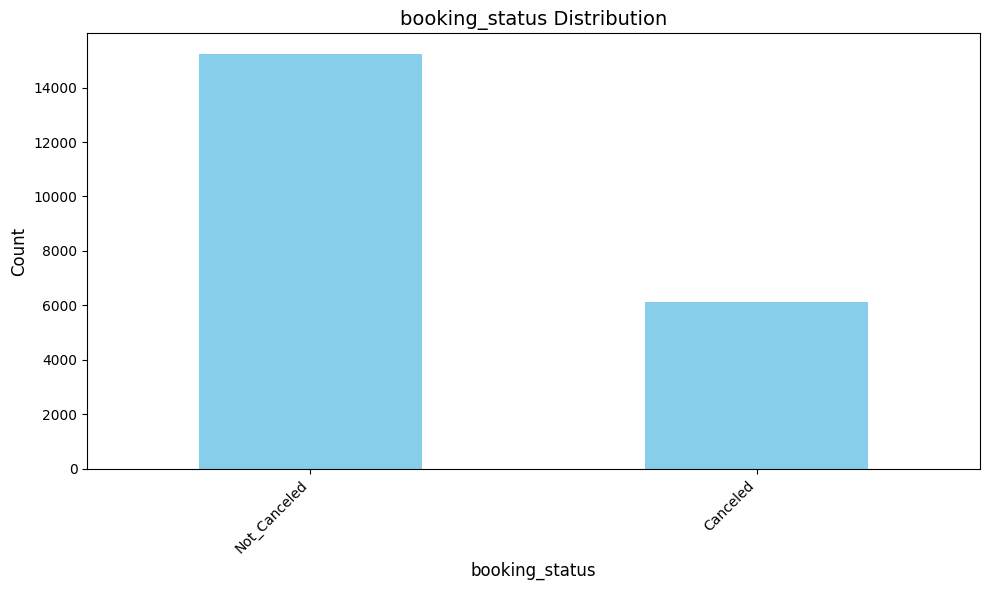

In [30]:
plot_categorical_distribution(data,cat_cols)

##### BIVARIANTE ANALYSIS :

In [31]:
def plot_bivariate_num(df: pd.DataFrame, target: str, num_features: list,
                       max_cols: int = 2, max_rows: int = 30, palette="Blues",
                       figsize_per_plot=(7,5)):

    if target not in df.columns:
        raise ValueError(f"La colonne cible '{target}' n'existe pas dans le DataFrame.")

    if len(num_features) == 0:
        print("Aucune colonne numérique fournie !")
        return

    if len(num_features) > max_rows:
        print(f"Attention : {len(num_features)} colonnes — affichage des {max_rows} premières.")
        num_features = num_features[:max_rows]

    # Calcul du nombre de lignes nécessaire
    n_plots = len(num_features)
    n_rows = int(np.ceil(n_plots / max_cols))
    n_cols = min(max_cols, n_plots)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(figsize_per_plot[0]*n_cols,
                                                    figsize_per_plot[1]*n_rows))
    axes = np.atleast_2d(axes).flatten()

    for i, col in enumerate(num_features):
        if col not in df.columns:
            print(f"Colonne '{col}' non trouvée dans le DataFrame, skipping.")
            continue

        sns.boxplot(x=target, y=col, data=df, ax=axes[i], palette=palette)
        axes[i].set_title(f"{col} VS {target}", fontsize=12)
        axes[i].set_xlabel(target)
        axes[i].set_ylabel(col)
        axes[i].tick_params(axis='x', rotation=45)

    # Supprimer axes inutilisés si nombre de plots < n_rows*n_cols
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


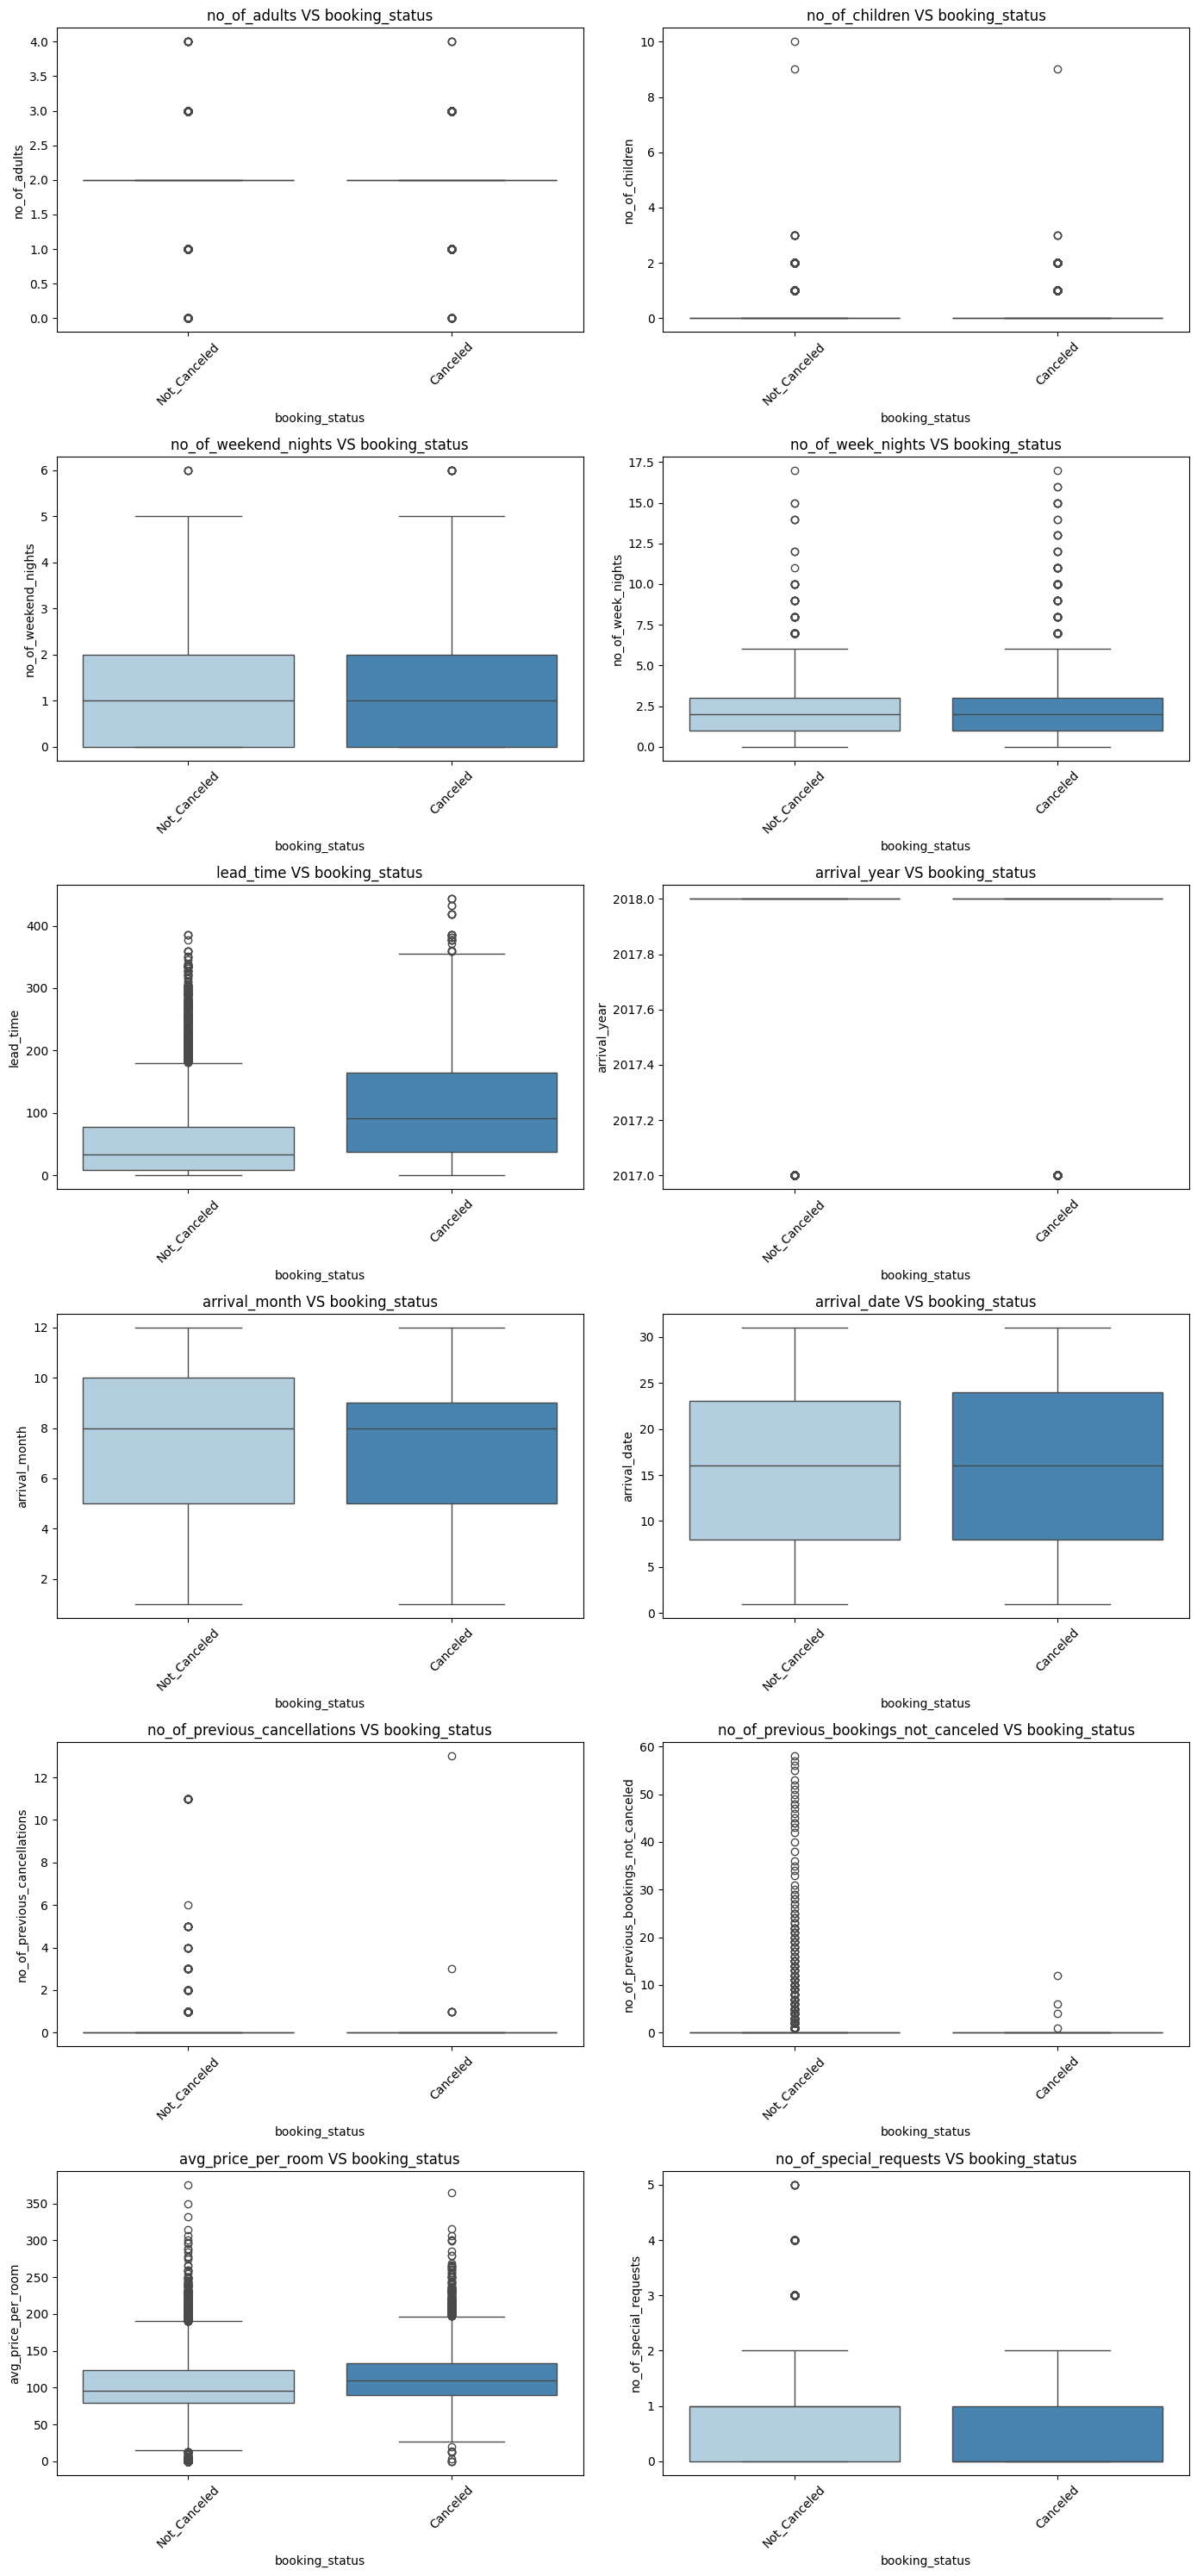

In [32]:
plot_bivariate_num(data,'booking_status',num_cols)

C’est parfait d'utiliser "sns.countplot" quand on veut comparer une variable catégorielle (feature) selon une autre catégorielle (target) en un seul appel :

In [33]:
def plot_bivaraite_cat(df: pd.DataFrame, target: str, cat_features: list):

    num_features = len(cat_features)
    num_rows = (num_features+1)//2

    fig , axes = plt.subplots(num_rows , 2 , figsize=(15 , num_rows*5))
    axes = axes.flatten()

    for i,feature in enumerate(cat_features):
        sns.countplot(x=feature , hue=target ,data=df , palette="Blues" , ax = axes[i])
        axes[i].set_title(f"{feature} VS {target}")
        axes[i].tick_params(axis='x' , rotation=90)

    plt.tight_layout()
    plt.show()

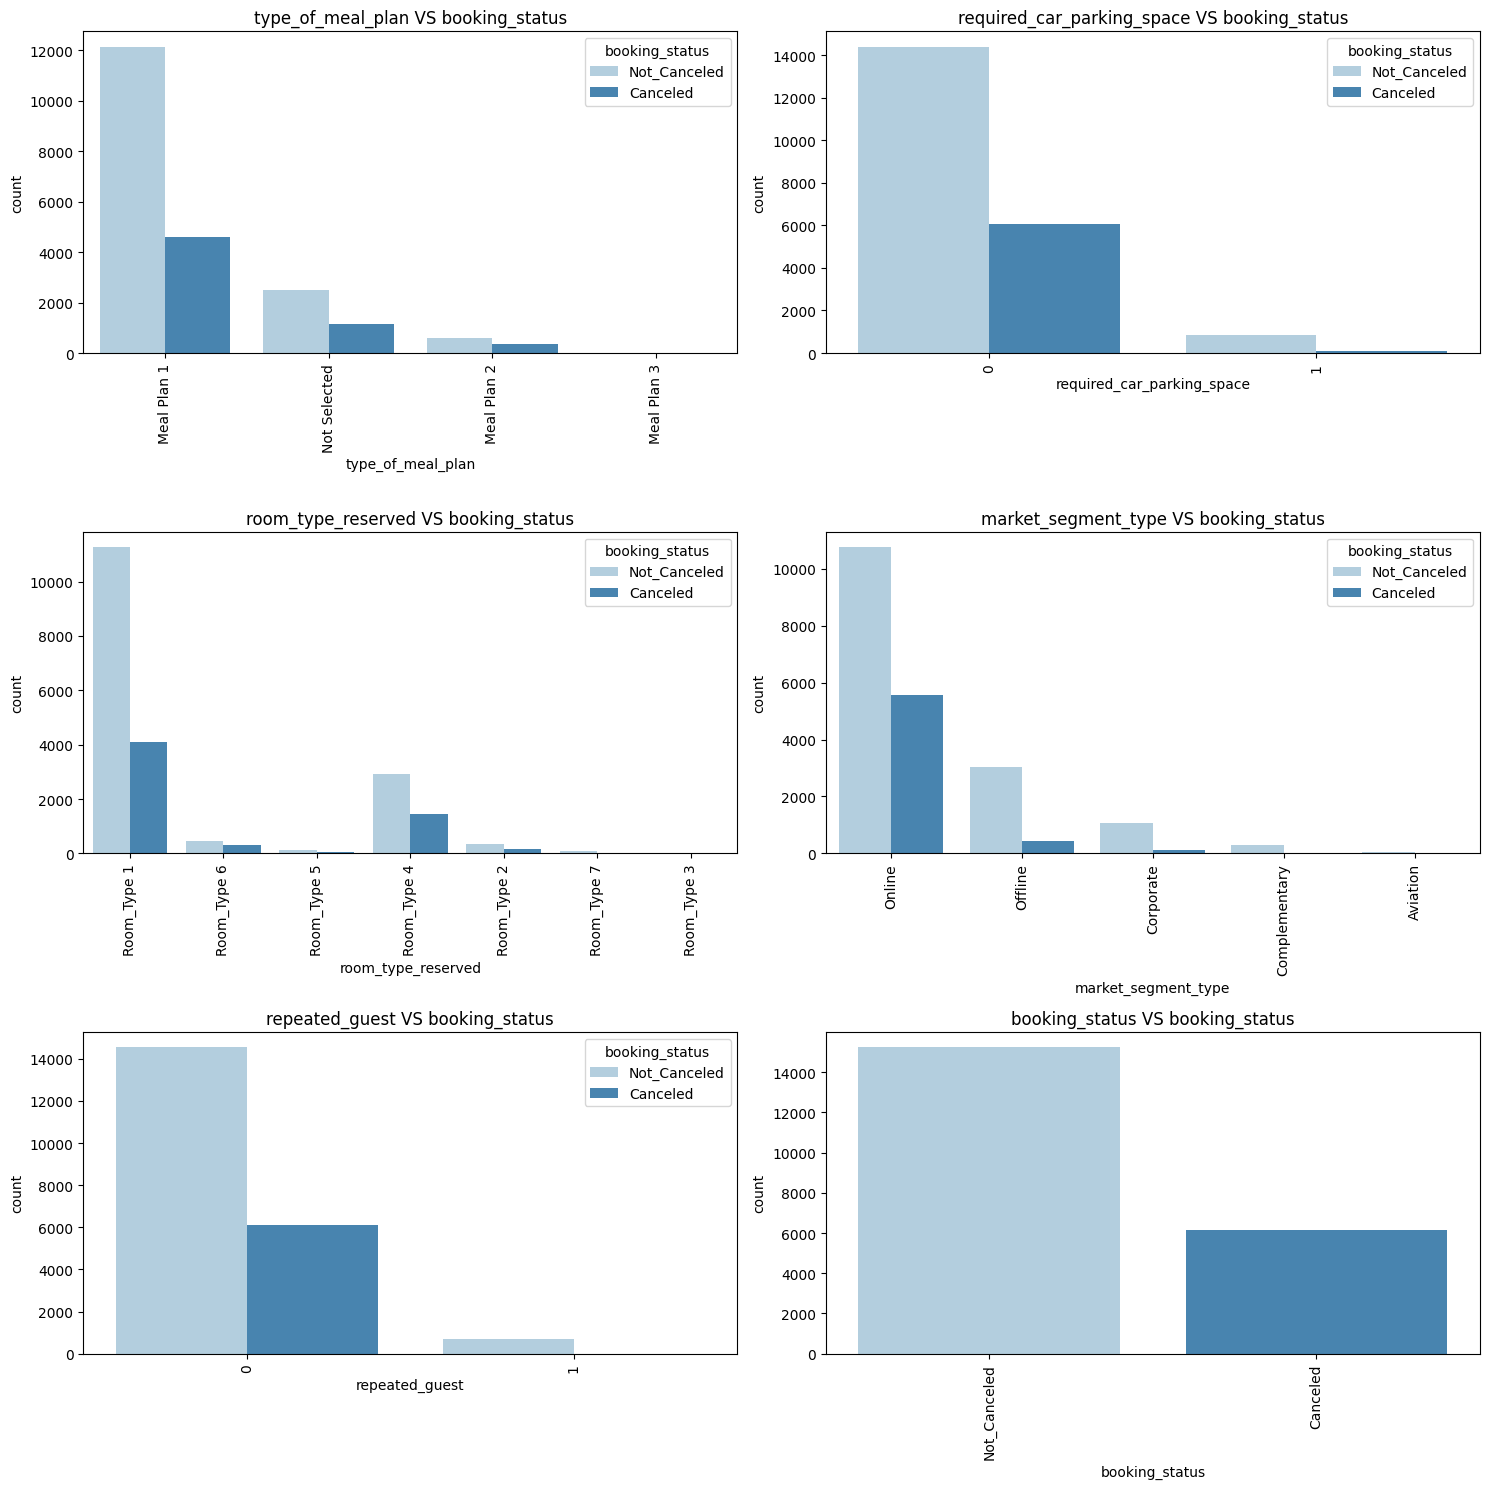

In [34]:
plot_bivaraite_cat(data,'booking_status',cat_cols)

N.B : Mais comme déja dit dans le cas des données de catégories, on utilise value_counts pour le regroupement et barplot (pour plus de controle).

#### DATA PREPROCESSING

LAbel Encoding :

In [35]:
from sklearn.preprocessing import LabelEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [36]:
encoder_label = LabelEncoder()

mapper = {}

for col in cat_cols:
    data[col] = encoder_label.fit_transform(data[col])
    mapper[col] = {label:code for label,code in zip(encoder_label.classes_ , encoder_label.transform(encoder_label.classes_))}



In [37]:
mapper

{'type_of_meal_plan': {'Meal Plan 1': np.int64(0),
  'Meal Plan 2': np.int64(1),
  'Meal Plan 3': np.int64(2),
  'Not Selected': np.int64(3)},
 'required_car_parking_space': {np.int64(0): np.int64(0),
  np.int64(1): np.int64(1)},
 'room_type_reserved': {'Room_Type 1': np.int64(0),
  'Room_Type 2': np.int64(1),
  'Room_Type 3': np.int64(2),
  'Room_Type 4': np.int64(3),
  'Room_Type 5': np.int64(4),
  'Room_Type 6': np.int64(5),
  'Room_Type 7': np.int64(6)},
 'market_segment_type': {'Aviation': np.int64(0),
  'Complementary': np.int64(1),
  'Corporate': np.int64(2),
  'Offline': np.int64(3),
  'Online': np.int64(4)},
 'repeated_guest': {np.int64(0): np.int64(0), np.int64(1): np.int64(1)},
 'booking_status': {'Canceled': np.int64(0), 'Not_Canceled': np.int64(1)}}

In [38]:
data.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,1,2,1,0,0,0,26,2017,10,17,4,0,0,0,161.00,0,1
1,2,1,1,1,0,0,0,98,2018,7,16,4,0,0,0,121.50,2,1
2,2,0,0,3,0,0,0,433,2018,9,8,3,0,0,0,70.00,0,0
3,2,0,2,5,0,0,0,195,2018,8,8,3,0,0,0,72.25,0,1
4,1,0,0,2,0,0,0,188,2018,6,15,3,0,0,0,130.00,0,0


Multicolinéarité : “trop de variables qui se ressemblent”.

In [39]:
X= add_constant(data)
X

,const,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,1.0,2,1,2,1,0,0,0,26,2017,10,17,4,0,0,0,161.00,0,1
1,1.0,2,1,1,1,0,0,0,98,2018,7,16,4,0,0,0,121.50,2,1
2,1.0,2,0,0,3,0,0,0,433,2018,9,8,3,0,0,0,70.00,0,0
3,1.0,2,0,2,5,0,0,0,195,2018,8,8,3,0,0,0,72.25,0,1
4,1.0,1,0,0,2,0,0,0,188,2018,6,15,3,0,0,0,130.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29012,1.0,3,0,0,1,0,0,3,65,2018,6,21,4,0,0,0,132.30,0,0
29013,1.0,2,0,2,3,0,0,0,86,2018,6,17,4,0,0,0,126.90,1,1
29014,1.0,2,0,0,2,0,0,3,0,2018,10,12,4,0,0,0,139.50,1,1
29015,1.0,2,0,2,2,0,0,0,43,2017,12,26,3,0,0,0,55.00,2,1


In [40]:
# calcule de la variance inflation factor de chaque variable afin de mesurer la multicolinéarité:

X = add_constant(data)

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                   for i in range(X.shape[1])]

print(vif_data)

'''
Si une variable a VIF > 5 ou 10, on envisage de la supprimer
ou de la combiner avec d’autres pour réduire la redondance.
'''




                                 feature           VIF
0                                  const  4.100197e+07
1                           no_of_adults  1.341180e+00
2                         no_of_children  1.282459e+00
3                   no_of_weekend_nights  1.073215e+00
4                      no_of_week_nights  1.125260e+00
5                      type_of_meal_plan  1.178228e+00
6             required_car_parking_space  1.036105e+00
7                     room_type_reserved  1.549859e+00
8                              lead_time  1.406287e+00
9                           arrival_year  1.288533e+00
10                         arrival_month  1.248028e+00
11                          arrival_date  1.003605e+00
12                   market_segment_type  1.704297e+00
13                        repeated_guest  1.765576e+00
14          no_of_previous_cancellations  1.396559e+00
15  no_of_previous_bookings_not_canceled  1.712854e+00
16                    avg_price_per_room  1.926372e+00
17        

'\nSi une variable a VIF > 5 ou 10, on envisage de la supprimer\nou de la combiner avec d’autres pour réduire la redondance.\n'

In [41]:
# correlation : aussi pour detecté une multicolinéarité
correlation = data.corr()

In [42]:
correlation

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
no_of_adults,1.000000,-0.049738,0.092764,0.114218,-0.005977,0.000419,0.275089,0.150995,0.096366,0.004833,0.018382,0.310783,-0.238974,-0.063739,-0.143903,0.327749,0.156833,-0.097198
no_of_children,-0.049738,1.000000,0.011033,0.019408,-0.102631,0.018089,0.351786,0.010094,0.036248,0.002606,0.027934,0.103359,-0.048678,-0.020954,-0.029112,0.352640,0.099069,-0.060030
no_of_weekend_nights,0.092764,0.011033,1.000000,0.223154,-0.041123,-0.057417,0.029964,0.131240,0.029016,0.011300,0.006921,0.091510,-0.088633,-0.028935,-0.040008,-0.003579,0.013803,-0.067944
no_of_week_nights,0.114218,0.019408,0.223154,1.000000,-0.073247,-0.061798,0.085547,0.223953,0.022199,0.030029,-0.000633,0.116978,-0.115186,-0.033133,-0.051829,0.018420,0.032304,-0.124415
type_of_meal_plan,-0.005977,-0.102631,-0.041123,-0.073247,1.000000,-0.024666,-0.245616,-0.055124,0.094627,0.008576,-0.006094,0.184654,-0.075476,-0.017205,-0.044891,-0.100708,-0.011933,-0.035864
required_car_parking_space,0.000419,0.018089,-0.057417,-0.061798,-0.024666,1.000000,0.016335,-0.046767,0.010158,-0.015330,-0.009352,-0.039210,0.113582,0.026876,0.066665,0.055536,0.075479,0.092511
room_type_reserved,0.275089,0.351786,0.029964,0.085547,-0.245616,0.016335,1.000000,-0.014666,0.090492,0.001906,0.024315,0.089176,-0.045353,-0.013842,-0.024727,0.490983,0.086319,-0.072128
lead_time,0.150995,0.010094,0.131240,0.223953,-0.055124,-0.046767,-0.014666,1.000000,0.169463,0.132140,0.034112,0.140396,-0.148948,-0.053930,-0.087026,-0.044061,-0.012787,-0.368151
arrival_year,0.096366,0.036248,0.029016,0.022199,0.094627,0.010158,0.090492,0.169463,1.000000,-0.322786,0.011340,0.111445,-0.010158,0.011111,0.025551,0.174569,0.000594,-0.149673
arrival_month,0.004833,0.002606,0.011300,0.030029,0.008576,-0.015330,0.001906,0.132140,-0.322786,1.000000,-0.020386,-0.017885,0.001744,-0.043586,-0.003881,0.066156,0.136037,0.015898


<Axes: >

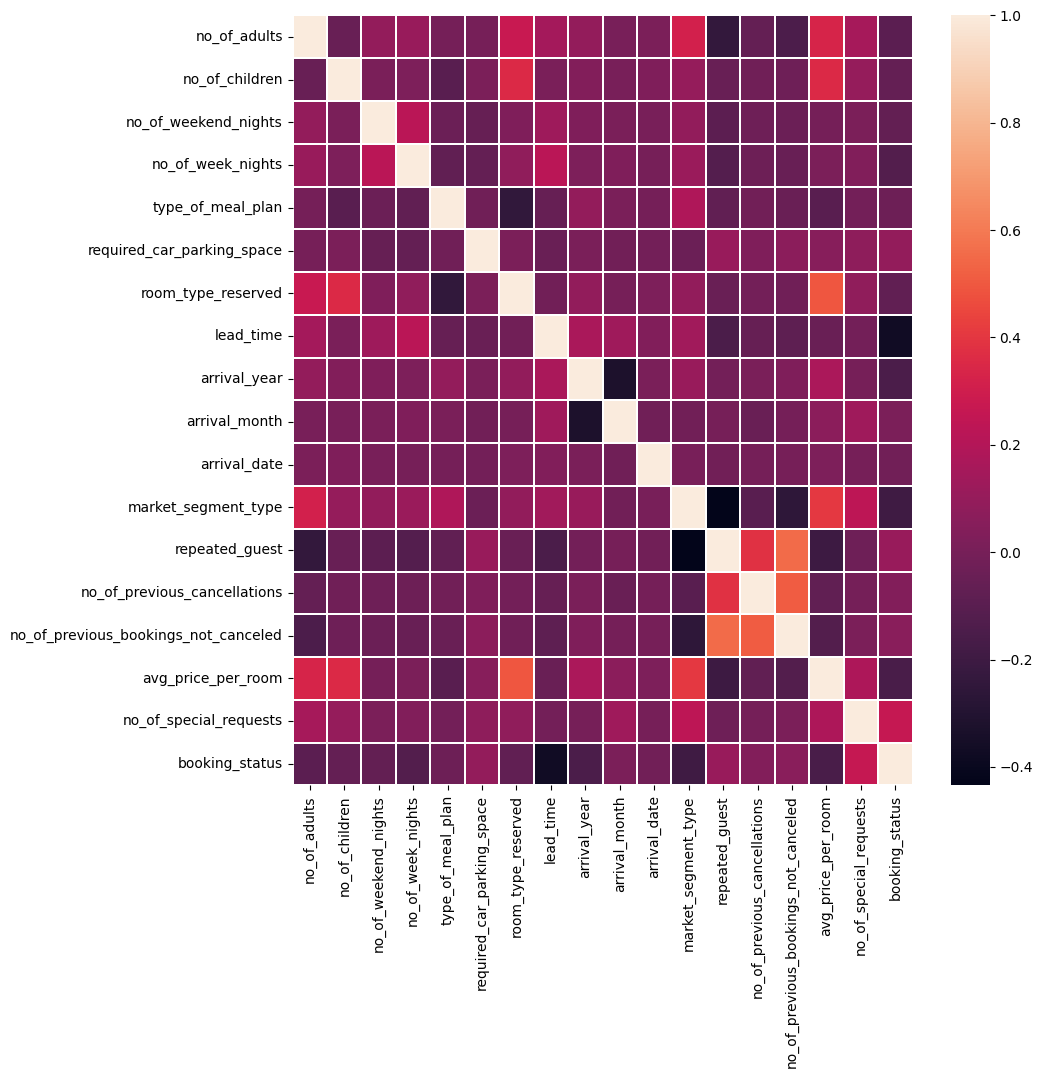

In [43]:
'''
C’est la fonction de Seaborn qui dessine une carte
de chaleur (heatmap).

Chaque case (cellule) est colorée selon la valeur
dans la matrice fournie (correlation ici).

Le heatmap est pratique dès qu’on veut visualiser
une matrice ou un tableau de valeurs numériques
'''
plt.figure(figsize=(10,10))
sns.heatmap(correlation,linewidths=0.2)

Asymètrie des variables : skewed data

🎯 Utilité pratique en préparation de données

Vérifier la normalité :

1) Beaucoup de modèles (ex : régressions linéaires, ANOVA) préfèrent des variables proches d’une distribution normale.

2) Skew élevé ⇒ appliquer une transformation (log, racine carrée, Box-Cox…).

Détection de valeurs extrêmes :

1) Une asymétrie marquée peut signaler la présence d’outliers.

Choix de la métrique / modélisation :

1) Si une variable est très skewed, il peut être préférable d’utiliser des modèles robustes ou de normaliser les données.

In [44]:
# ──────────────────────────────────────────────────────────────
# 🔹 Normalisation
#    Mise à l’échelle des valeurs dans une plage fixe (souvent 0–1).
#    Formule : (x - x_min) / (x_max - x_min)
#    ➤ Utile quand les algorithmes sont sensibles à l’échelle ou aux distances
#      (k-NN, réseaux de neurones, méthodes basées sur la distance euclidienne).
#     exemple [10,20,30] => [0,0.5,1]
#
# 🔹 Standardisation
#    Centrage et réduction pour obtenir moyenne = 0 et écart-type = 1.
#    Formule : (x - μ) / σ
#    ➤ Utile pour les modèles supposant des données centrées et comparables
#      (régression linéaire/logistique, SVM, PCA…).
#
# Remarque : Ni la normalisation ni la standardisation ne rendent
#            une distribution symétrique ; pour corriger l’asymétrie,
#            utiliser des transformations (log, Box-Cox, etc.).
# ──────────────────────────────────────────────────────────────

In [45]:
skewness  = data.skew()
skewness

,0
no_of_adults,-0.305652
no_of_children,4.165696
no_of_weekend_nights,0.636637
no_of_week_nights,1.553657
type_of_meal_plan,1.650716
required_car_parking_space,4.538315
room_type_reserved,1.392145
lead_time,1.405258
arrival_year,-1.953273
arrival_month,-0.293266


In [46]:

for col in data.columns:
    if skewness[col] > 5:
        data[col] = np.log1p(data[col])

In [47]:
skewness  = data.skew()
skewness

,0
no_of_adults,-0.305652
no_of_children,4.165696
no_of_weekend_nights,0.636637
no_of_week_nights,1.553657
type_of_meal_plan,1.650716
required_car_parking_space,4.538315
room_type_reserved,1.392145
lead_time,1.405258
arrival_year,-1.953273
arrival_month,-0.293266


Notre data est désiquilibré :

Gestion des données déséquilibrées (imbalanced data) :

1) Oversampling (SMOTE, ADASYN)<----

2) Undersampling

3) Pondération des classes (class weights).

👉 Très important pour classification binaire/multi-classes déséquilibrée (fraude, détection anomalies) => notre cas

In [49]:
data['booking_status'].value_counts()

,count
booking_status,
1,15231
0,6128


In [50]:
X = data.drop(columns=['booking_status'])
Y = data['booking_status']
X.columns

Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space',
       'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month',
       'arrival_date', 'market_segment_type', 'repeated_guest',
       'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled',
       'avg_price_per_room', 'no_of_special_requests'],
      dtype='object')

In [51]:
!pip install imbalanced-learn

In [52]:
# équilibrement :
from imblearn.over_sampling import SMOTE

In [53]:
smt = SMOTE(random_state=42)
X_resampled, y_resampled = smt.fit_resample(X, Y)


In [54]:
y_resampled.value_counts()

,count
booking_status,
1,15231
0,15231


In [57]:
print(type(y_resampled))
print(type(X_resampled))
X_resampled.head()

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests
0,2,1,2,1,0,0,0,26,2017,10,17,4,0.0,0.0,0.0,161.00,0
1,2,1,1,1,0,0,0,98,2018,7,16,4,0.0,0.0,0.0,121.50,2
2,2,0,0,3,0,0,0,433,2018,9,8,3,0.0,0.0,0.0,70.00,0
3,2,0,2,5,0,0,0,195,2018,8,8,3,0.0,0.0,0.0,72.25,0
4,1,0,0,2,0,0,0,188,2018,6,15,3,0.0,0.0,0.0,130.00,0


In [58]:
balanced_data = pd.concat([X_resampled, y_resampled], axis=1)

In [59]:
balanced_data.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,1,2,1,0,0,0,26,2017,10,17,4,0.0,0.0,0.0,161.00,0,1
1,2,1,1,1,0,0,0,98,2018,7,16,4,0.0,0.0,0.0,121.50,2,1
2,2,0,0,3,0,0,0,433,2018,9,8,3,0.0,0.0,0.0,70.00,0,0
3,2,0,2,5,0,0,0,195,2018,8,8,3,0.0,0.0,0.0,72.25,0,1
4,1,0,0,2,0,0,0,188,2018,6,15,3,0.0,0.0,0.0,130.00,0,0


In [60]:
balanced_data['booking_status'].value_counts()

,count
booking_status,
1,15231
0,15231


In [61]:
balanced_data.shape

(30462, 18)

In [62]:
data = balanced_data.copy()

Selection des prédecteur les plus ségnificative.

----> FEATURES SELECTION


In [63]:
data.shape

(30462, 18)

In [64]:
X = data.drop(columns='booking_status')
y = data['booking_status']

In [65]:
from sklearn.ensemble import RandomForestClassifier

In [66]:
modelRF = RandomForestClassifier(random_state=42)
modelRF.fit(X,y)

RandomForestClassifier(random_state=42)

In [78]:
feature_importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': modelRF.feature_importances_
}).sort_values(by='importance', ascending=False)

In [124]:
top_11_features = feature_importance_df["feature"].head(11).values

top_11 = data[top_11_features.tolist() + ["booking_status"]]

In [125]:
top_11

,lead_time,no_of_special_requests,avg_price_per_room,arrival_month,arrival_date,market_segment_type,no_of_week_nights,no_of_weekend_nights,type_of_meal_plan,room_type_reserved,no_of_adults,booking_status
0,26,0,161.000000,10,17,4,1,2,0,0,2,1
1,98,2,121.500000,7,16,4,1,1,0,0,2,1
2,433,0,70.000000,9,8,3,3,0,0,0,2,0
3,195,0,72.250000,8,8,3,5,2,0,0,2,1
4,188,0,130.000000,6,15,3,2,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
30457,265,0,111.037207,6,24,3,2,0,1,0,2,0
30458,103,0,72.250000,4,18,3,3,1,0,0,1,0
30459,27,0,104.556265,6,12,4,2,1,1,0,2,0
30460,46,0,107.100000,4,4,4,1,1,3,0,1,0


In [126]:
data = top_11.copy()

In [127]:
data.head()
data.shape

(30462, 12)

#### Model Selection :

In [90]:
!pip install xgboost lightgbm

In [92]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score


In [128]:
X = data.drop(columns='booking_status')
y = data['booking_status']

X_train , X_test , y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [129]:
metrics = {
    "Model":[ ],
    "Accuracy": [],
    "Precision" : [],
    "Recall": [],
    "F1 Score": []
}

classificateurs = {
    "LogisticRegression" : LogisticRegression(random_state=42),
    "Gradient Boosting" : GradientBoostingClassifier(random_state=42),
    "Suuport vector classifier" : SVC(random_state=42),
    "Random Forest" : RandomForestClassifier(random_state=42),
    "KNeighborsClassifier" : KNeighborsClassifier(),
    "XGBoost" : XGBClassifier(random_state=42),
    "LightGBM" : LGBMClassifier(random_state=42),
    "Naive Bayes" : GaussianNB(),
    "AdaBoost" : AdaBoostClassifier(random_state=42),
    "Decision Tree" : DecisionTreeClassifier(random_state=42)
}

In [130]:
for name, model in classificateurs.items():
  model.fit(X_train,y_train)
  y_pred = model.predict(X_test)

  metrics["Model"].append(name)
  metrics["Accuracy"].append(accuracy_score(y_test,y_pred))
  metrics["Precision"].append(precision_score(y_test,y_pred))
  metrics["Recall"].append(recall_score(y_test,y_pred))
  metrics["F1 Score"].append(f1_score(y_test,y_pred))

[LightGBM] [Info] Number of positive: 12161, number of negative: 12208
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003726 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 606
[LightGBM] [Info] Number of data points in the train set: 24369, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499036 -> initscore=-0.003857
[LightGBM] [Info] Start training from score -0.003857


In [131]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,Model,Accuracy,Precision,Recall,F1 Score
0,LogisticRegression,0.778763,0.802317,0.744300,0.772220
1,Gradient Boosting,0.836370,0.820402,0.864495,0.841872
2,Suuport vector classifier,0.722140,0.730653,0.710423,0.720396
3,Random Forest,0.892664,0.892973,0.894137,0.893555
4,KNeighborsClassifier,0.779255,0.856258,0.675244,0.755054
5,XGBoost,0.876908,0.873952,0.883062,0.878483
6,LightGBM,0.865255,0.851077,0.887948,0.869122
7,Naive Bayes,0.771705,0.802523,0.725407,0.762019
8,AdaBoost,0.804202,0.821294,0.781433,0.800868
9,Decision Tree,0.844576,0.858494,0.828013,0.842978


 TRAIN THE WINNER PROPERLY :

In [132]:
# la recherche d’hyperparamètres (hyperparameter tuning).
from sklearn.model_selection import RandomizedSearchCV

In [133]:
X = data.drop(columns='booking_status')
y = data["booking_status"]

X_train , X_test , y_train , y_test = train_test_split(X,y , test_size=0.2 , random_state=42)

In [134]:
model = RandomForestClassifier(random_state = 42)
from scipy.stats import randint

In [135]:
params_for_test={
    'n_estimators' : randint(100,500),
    'max_depth' : randint(10,50),
    'min_samples_split': randint(2,10),
    'min_samples_leaf' : randint(1,5),
    'bootstrap' : [True , False]
}

In [136]:
random_search = RandomizedSearchCV(
    estimator=model,                     # le modèle à optimiser
    param_distributions=params_for_test, # les plages de valeurs à tester
    n_iter=5,                            # nombre de combinaisons à tester
    cv=5,                                # validation croisée à 5 folds
    verbose=2,                           # pour afficher la progression
    random_state=42,                     # pour reproductibilité
    scoring='accuracy'                   # métrique utilisée pour évaluer chaque essai
)


In [137]:
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END bootstrap=True, max_depth=38, min_samples_leaf=3, min_samples_split=4, n_estimators=171; total time=   5.3s
[CV] END bootstrap=True, max_depth=38, min_samples_leaf=3, min_samples_split=4, n_estimators=171; total time=   4.4s
[CV] END bootstrap=True, max_depth=38, min_samples_leaf=3, min_samples_split=4, n_estimators=171; total time=   5.1s
[CV] END bootstrap=True, max_depth=38, min_samples_leaf=3, min_samples_split=4, n_estimators=171; total time=   5.0s
[CV] END bootstrap=True, max_depth=38, min_samples_leaf=3, min_samples_split=4, n_estimators=171; total time=   4.6s
[CV] END bootstrap=True, max_depth=30, min_samples_leaf=3, min_samples_split=3, n_estimators=314; total time=   9.5s
[CV] END bootstrap=True, max_depth=30, min_samples_leaf=3, min_samples_split=3, n_estimators=314; total time=   9.2s
[CV] END bootstrap=True, max_depth=30, min_samples_leaf=3, min_samples_split=3, n_estimators=314; total time=   8.5s
[CV]

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=5,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a6f30fa0b90>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a6f30fa3f50>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a6f30fa1250>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a6f30fa2d50>},
                   random_state=42, scoring='accuracy', verbose=2)

In [138]:
random_search.best_params_

{'bootstrap': False,
 'max_depth': 33,
 'min_samples_leaf': 3,
 'min_samples_split': 7,
 'n_estimators': 408}

In [139]:
finalModel = random_search.best_estimator_

In [140]:
# test :
y_pred = finalModel.predict(X_test)

In [141]:
metricsFinal = {
    "Accuracy":0 ,
    "Precision" :0,
    "Recall":0,
    "F1 Score":0
}

In [142]:
metricsFinal['Accuracy'] = accuracy_score(y_test,y_pred)
metricsFinal['Precision'] = precision_score(y_test,y_pred)
metricsFinal['Recall'] = recall_score(y_test,y_pred)
metricsFinal['F1 Score'] = f1_score(y_test,y_pred)

In [143]:
metricsFinal_df = pd.DataFrame(metricsFinal , index=[0])
metricsFinal_df

,Accuracy,Precision,Recall,F1 Score
0,0.892992,0.888746,0.900326,0.894498


MONTER SUR LE DRIVE :

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

print("Google Drive est monté !")

In [144]:
import joblib

In [145]:
# enregistrement dans le drive

# dossie dans Drive
model_path = '/content/drive/MyDrive/Colab Notebooks/MLOPS-hotelReservation/final_model.pkl'

# Sauvegarde du modèle
joblib.dump(finalModel, model_path)

print(f"✅ Modèle sauvegardé à : {model_path}")

✅ Modèle sauvegardé à : /content/drive/MyDrive/Colab Notebooks/MLOPS-hotelReservation/final_model.pkl


In [146]:
# chargement à partir de drive :

finalModel_loaded = joblib.load(model_path)

print("✅ Modèle chargé avec succès !")

✅ Modèle chargé avec succès !


In [147]:
data

,lead_time,no_of_special_requests,avg_price_per_room,arrival_month,arrival_date,market_segment_type,no_of_week_nights,no_of_weekend_nights,type_of_meal_plan,room_type_reserved,no_of_adults,booking_status
0,26,0,161.000000,10,17,4,1,2,0,0,2,1
1,98,2,121.500000,7,16,4,1,1,0,0,2,1
2,433,0,70.000000,9,8,3,3,0,0,0,2,0
3,195,0,72.250000,8,8,3,5,2,0,0,2,1
4,188,0,130.000000,6,15,3,2,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
30457,265,0,111.037207,6,24,3,2,0,1,0,2,0
30458,103,0,72.250000,4,18,3,3,1,0,0,1,0
30459,27,0,104.556265,6,12,4,2,1,1,0,2,0
30460,46,0,107.100000,4,4,4,1,1,3,0,1,0


In [164]:
# Exemple : une seule observation (remplacer les valeurs selon ton dataset)
nouvelle_reservation = pd.DataFrame({
    'lead_time':[600],
    'no_of_special_requests':[3],
    'avg_price_per_room':[320],
    'arrival_month':[1],
    'arrival_date':	[24],
    'market_segment_type':[4],
    'no_of_week_nights':[5],
    'no_of_weekend_nights':[2],
    'type_of_meal_plan'	:[1],
    'room_type_reserved':	[1],
    'no_of_adults': [2]
})

# Prédire
prediction = finalModel_loaded.predict(nouvelle_reservation)

print("🧾 Statut prédit :", "Non annulée" if prediction[0] == 1 else "Annulée")

🧾 Statut prédit : Non annulée
